In [1]:
import numpy as np
import torch
import torch.nn as nn
from utils import WaveformDataset
from torch.utils.data import DataLoader
from model import DDPMWaveDenoiser1D
import matplotlib.pyplot as plt
import os

In [8]:
device = "cuda"
save_dir = "./save_data"

In [11]:
train_m = WaveformDataset(
    r"D:/VAE_GAN_DM/latent_bits_M/bits_8/latent_tran_encode"
)

train_f = WaveformDataset(
    r"D:/VAE_GAN_DM/latent_bits_F/bits_8/latent_tran_encode"
)

train_dl_m = DataLoader(
    train_m,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

train_dl_f = DataLoader(
    train_f,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

model = DDPMWaveDenoiser1D().to(device)
model.load_state_dict(
    torch.load(
        "./save_model/wave_denoiser.pth",
        map_location=device
    )
)
print("loaded")

min_len = 3808
min_len = 3808
loaded


In [12]:
# ===== DDPM schedule =====
T = 1000

betas = torch.linspace(1e-4, 0.02, T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

In [13]:
t_list = [50, 100, 200, 300, 400, 500, 700, 900]

improve_list = []
corr_list = []
noise_mse_list = []

In [17]:
model.eval()

with torch.no_grad():

    (x_m, target), (x_f, interference) = next(
        iter(zip(train_dl_m, train_dl_f))
    )

    target = target.to(device).float()
    interference = interference.to(device).float()

    pred = target[0].detach().cpu().numpy()    # [2, 3808]

    I = pred[0]
    Q = pred[1]

    tmp = np.empty(2 * I.shape[0], dtype=np.float32)
    tmp[0::2] = I.astype(np.float32)
    tmp[1::2] = Q.astype(np.float32)

    tmp.tofile(os.path.join(save_dir, "target.bin"))

    print("target saved")
    print("I/Q length:", I.shape[0])
    print("saved length:", tmp.shape[0])

    pred = interference[0].detach().cpu().numpy()    # [2, 3808]

    I = pred[0]
    Q = pred[1]

    tmp = np.empty(2 * I.shape[0], dtype=np.float32)
    tmp[0::2] = I.astype(np.float32)
    tmp[1::2] = Q.astype(np.float32)

    tmp.tofile(os.path.join(save_dir, "interference.bin"))

    print("interference saved")
    print("I/Q length:", I.shape[0])
    print("saved length:", tmp.shape[0])

    # ===== 跟 training 一樣 normalize =====
    target = target / (
        torch.sqrt(
            torch.mean(target**2, dim=(1,2), keepdim=True)
        ) + 1e-8
    )

    interference = interference / (
        torch.sqrt(
            torch.mean(interference**2, dim=(1,2), keepdim=True)
        ) + 1e-8
    )

    B = target.shape[0]

    for t_val in t_list:

        t = torch.full(
            (B,),
            t_val,
            device=device,
            dtype=torch.long
        )

        sqrt_ab = torch.sqrt(
            alpha_bars[t]
        )[:, None, None]

        sqrt_1mab = torch.sqrt(
            1 - alpha_bars[t]
        )[:, None, None]

        # ===== noisy signal =====
        x_t = (
            sqrt_ab * target
            + sqrt_1mab * interference
        )

        # ===== predict noise =====
        pred_noise = model(x_t, t)

        # ===== reconstruct clean =====
        pred_clean = (
            x_t - sqrt_1mab * pred_noise
        ) / sqrt_ab

        pred_clean_np = pred_clean.detach().cpu().numpy()

        # ===== 第一筆 sample，存成 MATLAB 一樣的格式 =====
        pred = pred_clean_np[0]   # [2, 3808]

        I = pred[0]
        Q = pred[1]

        tmp = np.empty(2 * I.shape[0], dtype=np.float32)
        tmp[0::2] = I.astype(np.float32)
        tmp[1::2] = Q.astype(np.float32)

        tmp.tofile(os.path.join(save_dir, "pred_clean.bin"))

        print("pred_clean saved")
        print("I/Q length:", I.shape[0])
        print("saved length:", tmp.shape[0])

        # ===== metrics =====
        mse_mix = torch.mean(
            (x_t - target) ** 2
        ).item()

        mse_pred = torch.mean(
            (pred_clean - target) ** 2
        ).item()

        improvement_db = 10 * np.log10(
            mse_mix / mse_pred
        )

        corr = torch.mean(
            pred_noise * interference
        ) / (
            torch.sqrt(torch.mean(pred_noise**2))
            * torch.sqrt(torch.mean(interference**2))
            + 1e-8
        )

        noise_mse = torch.mean(
            (pred_noise - interference)**2
        ).item()

        improve_list.append(improvement_db)
        corr_list.append(corr.item())
        noise_mse_list.append(noise_mse)

        print(
            f"t={t_val} | "
            f"Improve={improvement_db:.2f} dB | "
            f"Corr={corr.item():.3f} | "
            f"NoiseMSE={noise_mse:.3f}"
        )

target saved
I/Q length: 3808
saved length: 7616
interference saved
I/Q length: 3808
saved length: 7616
pred_clean saved
I/Q length: 3808
saved length: 7616
t=50 | Improve=-0.17 dB | Corr=0.217 | NoiseMSE=1.001
pred_clean saved
I/Q length: 3808
saved length: 7616
t=100 | Improve=0.05 dB | Corr=0.389 | NoiseMSE=0.882
pred_clean saved
I/Q length: 3808
saved length: 7616
t=200 | Improve=0.72 dB | Corr=0.648 | NoiseMSE=0.581
pred_clean saved
I/Q length: 3808
saved length: 7616
t=300 | Improve=0.94 dB | Corr=0.799 | NoiseMSE=0.361
pred_clean saved
I/Q length: 3808
saved length: 7616
t=400 | Improve=1.26 dB | Corr=0.903 | NoiseMSE=0.184
pred_clean saved
I/Q length: 3808
saved length: 7616
t=500 | Improve=1.39 dB | Corr=0.959 | NoiseMSE=0.080
pred_clean saved
I/Q length: 3808
saved length: 7616
t=700 | Improve=0.94 dB | Corr=0.995 | NoiseMSE=0.009
pred_clean saved
I/Q length: 3808
saved length: 7616
t=900 | Improve=-4.87 dB | Corr=0.999 | NoiseMSE=0.001


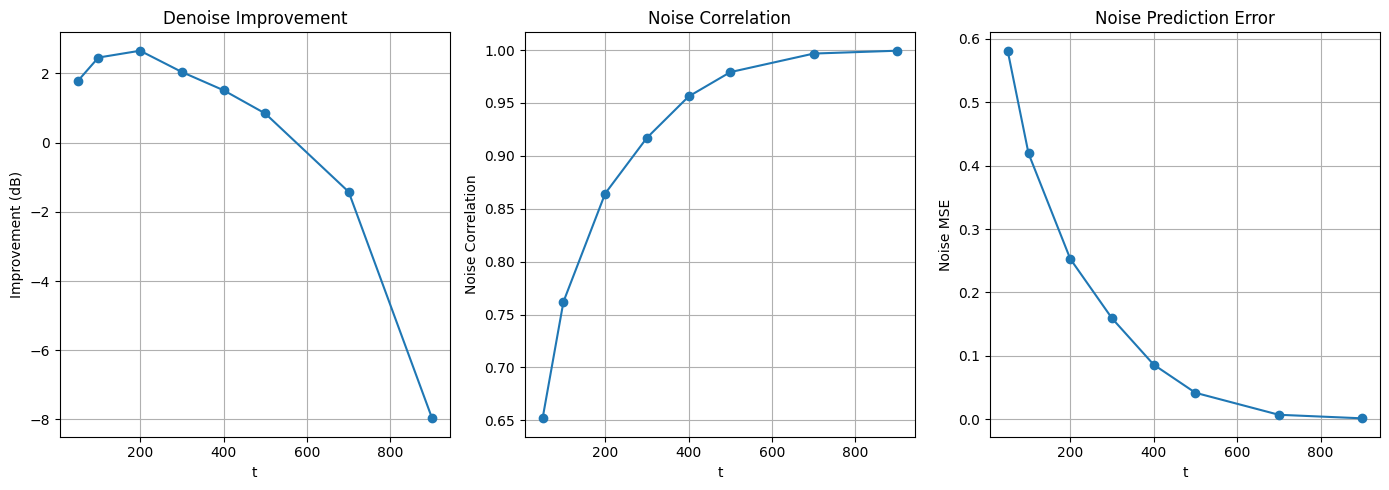

In [15]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
plt.plot(t_list, improve_list, marker='o')
plt.xlabel("t")
plt.ylabel("Improvement (dB)")
plt.title("Denoise Improvement")
plt.grid(True)

plt.subplot(1,3,2)
plt.plot(t_list, corr_list, marker='o')
plt.xlabel("t")
plt.ylabel("Noise Correlation")
plt.title("Noise Correlation")
plt.grid(True)

plt.subplot(1,3,3)
plt.plot(t_list, noise_mse_list, marker='o')
plt.xlabel("t")
plt.ylabel("Noise MSE")
plt.title("Noise Prediction Error")
plt.grid(True)

plt.tight_layout()
plt.show()